# Layer-wise Probing of BERT on SentEval Linguistic Tasks

Probing tasks (Conneau et al., 2018, [arXiv:1803.05449](https://arxiv.org/abs/1803.05449)):

| Task | File | Type | Labels |
|---|---|---|---|
| Sentence Length (SentLen) | `sentence_length.txt` | surface | 6 length bins (0-5) |
| Bigram Shift (BShift) | `bigram_shift.txt` | syntactic | `O` original / `I` two adjacent words inverted |
| Subject Number (SubjNum) | `subj_number.txt` | semantic | `NN` singular / `NNS` plural subject of main clause |

**Pipeline**
1. Download the three files from SentEval's `data/probing` folder.
2. Draw **50,000 class-balanced samples** per task.
3. **Stratified 90:10** train/test split.
4. Run a (frozen) BERT encoder, mean-pool the tokens of every encoder layer to get a sentence vector per layer.
5. Train **one logistic-regression probe per layer** (12 per task, 36 in total) and compare test accuracy across layers and tasks.

In [1]:
!pip install -q torch transformers scikit-learn pandas matplotlib tqdm requests

In [2]:
import os, random, time, urllib.request
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

# ----------------------------- Configuration -----------------------------
SEED        = 42
N_SAMPLES   = 50_000          # per task
TEST_SIZE   = 0.10            # 90:10 split
MODEL_NAME  = "bert-base-uncased"   # 12 encoder layers. For a lighter model try e.g.
                                    # "google/bert_uncased_L-4_H-512_A-8" (4 layers) - everything adapts automatically.
POOLING     = "mean"          # "mean" (mask-aware average of tokens) or "cls"
MAX_LEN     = 64
BATCH_SIZE  = 256
DATA_DIR    = "probing_data"
BASE_URL    = "https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing/"
TASKS = {
    "SentLen": "sentence_length.txt",
    "BShift":  "bigram_shift.txt",
    "SubjNum": "subj_number.txt",
}

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 1. Download and load the data

Each line is `split<TAB>label<TAB>sentence`. SentEval's original `tr/va/te` split is ignored: all rows are pooled, then we create our own balanced sample and 90:10 split.

In [3]:
os.makedirs(DATA_DIR, exist_ok=True)
for fname in TASKS.values():
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        print("Downloading", fname)
        urllib.request.urlretrieve(BASE_URL + fname, path)

def load_probing_file(path):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split("\t", 2)   # manual split: sentences may contain quotes
            if len(parts) == 3:
                rows.append((parts[1], parts[2]))
    return pd.DataFrame(rows, columns=["label", "sentence"])

raw = {t: load_probing_file(os.path.join(DATA_DIR, f)) for t, f in TASKS.items()}
for t, df in raw.items():
    print(f"{t}: {len(df):,} rows | classes: {sorted(df.label.unique())}")
    print(df.label.value_counts().sort_index().to_dict())

SentLen: 119,988 rows | classes: ['0', '1', '2', '3', '4', '5']
{'0': 19998, '1': 19998, '2': 19998, '3': 19998, '4': 19998, '5': 19998}
BShift: 120,000 rows | classes: ['I', 'O']
{'I': 60000, 'O': 60000}
SubjNum: 120,000 rows | classes: ['NN', 'NNS']
{'NN': 60000, 'NNS': 60000}


## 2. Balanced 50,000-sample subsets and stratified 90:10 split

In [4]:
def balanced_sample(df, n_total, seed=SEED):
    """Draw n_total rows with (as near as possible) equal rows per class.
    If n_total isn't divisible by the number of classes, the remainder is spread one-per-class."""
    classes = sorted(df.label.unique())
    base, rem = divmod(n_total, len(classes))
    parts = []
    for i, c in enumerate(classes):
        k = base + (1 if i < rem else 0)
        sub = df[df.label == c]
        assert len(sub) >= k, f"class {c} has only {len(sub)} rows, need {k}"
        parts.append(sub.sample(n=k, random_state=seed))
    return pd.concat(parts).sample(frac=1.0, random_state=seed).reset_index(drop=True)

data = {}
for t, df in raw.items():
    sub = balanced_sample(df, N_SAMPLES)
    labels = sorted(sub.label.unique())
    lab2id = {l: i for i, l in enumerate(labels)}
    y = sub.label.map(lab2id).values
    X_tr, X_te, y_tr, y_te = train_test_split(
        sub.sentence.tolist(), y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
    data[t] = dict(X_tr=X_tr, X_te=X_te, y_tr=y_tr, y_te=y_te, labels=labels)
    print(f"{t}: total={len(sub):,} train={len(X_tr):,} test={len(X_te):,}")
    print("   train class counts:", np.bincount(y_tr).tolist(), "| test class counts:", np.bincount(y_te).tolist())

SentLen: total=50,000 train=45,000 test=5,000
   train class counts: [7500, 7500, 7500, 7500, 7500, 7500] | test class counts: [834, 834, 833, 833, 833, 833]
BShift: total=50,000 train=45,000 test=5,000
   train class counts: [22500, 22500] | test class counts: [2500, 2500]
SubjNum: total=50,000 train=45,000 test=5,000
   train class counts: [22500, 22500] | test class counts: [2500, 2500]


## 3. Frozen BERT: per-layer sentence representations

`output_hidden_states=True` returns 13 tensors (embedding output + 12 encoder layers); we keep the **12 encoder layers**. Each sentence vector is the attention-mask-aware mean of its token vectors (or `[CLS]` if `POOLING="cls"`). BERT is used purely as a feature extractor (no fine-tuning).

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
encoder = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
N_LAYERS = encoder.config.num_hidden_layers
print(f"{MODEL_NAME}: {N_LAYERS} encoder layers, hidden size {encoder.config.hidden_size}")

@torch.no_grad()
def extract_features(sentences, batch_size=BATCH_SIZE):
    """Returns float32 array [N, N_LAYERS, hidden]."""
    # sort by length for fast batching, restore order afterwards
    order = np.argsort([len(s) for s in sentences])
    out = np.zeros((len(sentences), N_LAYERS, encoder.config.hidden_size), dtype=np.float32)
    use_amp = device == "cuda"
    for i in tqdm(range(0, len(sentences), batch_size), leave=False):
        idx = order[i:i + batch_size]
        enc = tokenizer([sentences[j] for j in idx], padding=True, truncation=True,
                        max_length=MAX_LEN, return_tensors="pt").to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            hs = encoder(**enc, output_hidden_states=True).hidden_states[1:]   # drop embedding layer
        hs = torch.stack(hs, dim=1).float()                                   # [B, L, T, H]
        if POOLING == "cls":
            rep = hs[:, :, 0, :]
        else:
            m = enc["attention_mask"][:, None, :, None].float()
            rep = (hs * m).sum(2) / m.sum(2)
        out[idx] = rep.cpu().numpy()
    return out

features = {}
for t, d in data.items():
    t0 = time.time()
    features[t] = dict(train=extract_features(d["X_tr"]), test=extract_features(d["X_te"]))
    print(f"{t}: train {features[t]['train'].shape}, test {features[t]['test'].shape}  ({time.time()-t0:.0f}s)")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

...

  0%|          | 0/20 [00:00<?, ?it/s]

BShift: train (45000, 12, 768), test (5000, 12, 768)  (18s)


  0%|          | 0/176 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

SubjNum: train (45000, 12, 768), test (5000, 12, 768)  (19s)


## 4. Train one logistic-regression probe per layer

Features are standardised (fit on train only) and a multinomial logistic regression is trained for each of the 12 layers, for each task.

In [6]:
results = {t: [] for t in data}          # test accuracy per layer
train_results = {t: [] for t in data}    # train accuracy per layer (to check over/underfitting)

for t, d in data.items():
    for layer in tqdm(range(N_LAYERS), desc=f"Probing {t}"):
        Xtr = features[t]["train"][:, layer, :]
        Xte = features[t]["test"][:, layer, :]
        clf = make_pipeline(StandardScaler(),
                            LogisticRegression(max_iter=1000, C=1.0, random_state=SEED))
        clf.fit(Xtr, d["y_tr"])
        results[t].append(accuracy_score(d["y_te"], clf.predict(Xte)))
        train_results[t].append(accuracy_score(d["y_tr"], clf.predict(Xtr)))
    print(t, "test acc per layer:", [round(a * 100, 1) for a in results[t]])

Probing SentLen:   0%|          | 0/12 [00:00<?, ?it/s]

SentLen test acc per layer: [95.7, 95.4, 95.5, 94.3, 93.9, 92.1, 91.5, 90.1, 88.6, 86.5, 84.3, 83.0]


Probing BShift:   0%|          | 0/12 [00:00<?, ?it/s]

BShift test acc per layer: [57.2, 70.9, 83.1, 86.2, 87.9, 88.5, 90.1, 91.1, 91.0, 89.8, 89.5, 88.1]


Probing SubjNum:   0%|          | 0/12 [00:00<?, ?it/s]

SubjNum test acc per layer: [84.0, 84.6, 84.9, 85.5, 88.0, 87.8, 88.8, 88.1, 88.3, 87.9, 87.3, 86.8]


## 5. Results

In [7]:
layers = list(range(1, N_LAYERS + 1))
res_df = pd.DataFrame({t: np.array(v) * 100 for t, v in results.items()}, index=pd.Index(layers, name="Layer")).round(2)
display(res_df)
print("\nBest layer per task:")
for t in res_df.columns:
    print(f"  {t:8s}: layer {res_df[t].idxmax():2d}  ->  {res_df[t].max():.2f}%   (chance = {100/len(data[t]['labels']):.1f}%)")
res_df.to_csv("probing_results.csv")

,SentLen,BShift,SubjNum
Layer,,,
1,95.68,57.16,84.02
2,95.36,70.94,84.56
3,95.50,83.10,84.92
4,94.34,86.18,85.48
5,93.86,87.94,87.98
6,92.10,88.54,87.76
7,91.46,90.10,88.84
8,90.12,91.10,88.10
9,88.62,90.98,88.32



Best layer per task:
  SentLen : layer  1  ->  95.68%   (chance = 16.7%)
  BShift  : layer  8  ->  91.10%   (chance = 50.0%)
  SubjNum : layer  7  ->  88.84%   (chance = 50.0%)


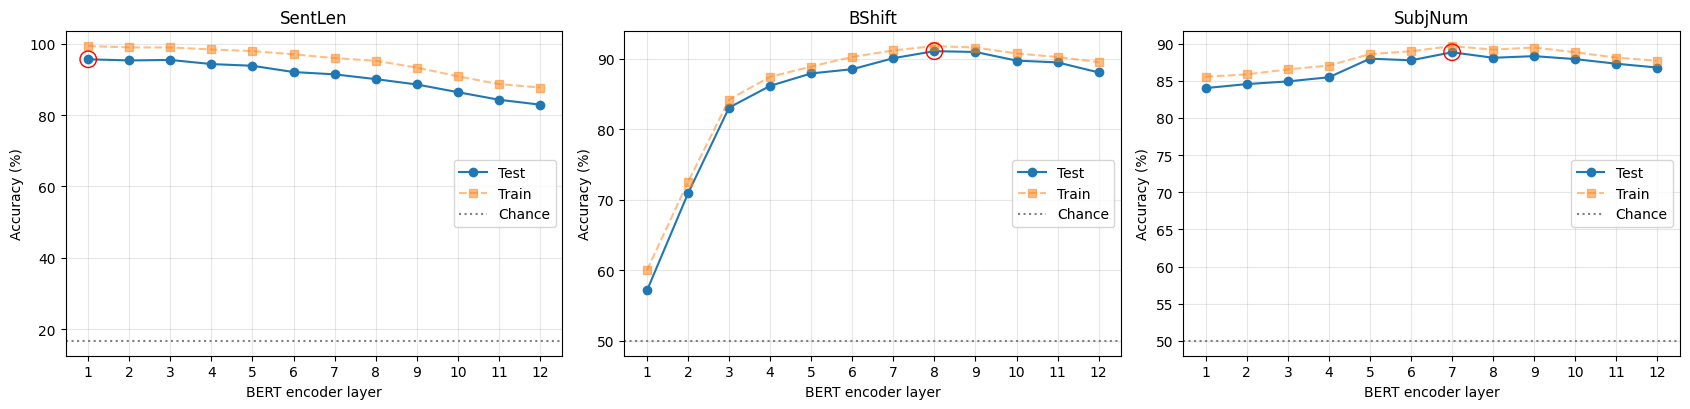

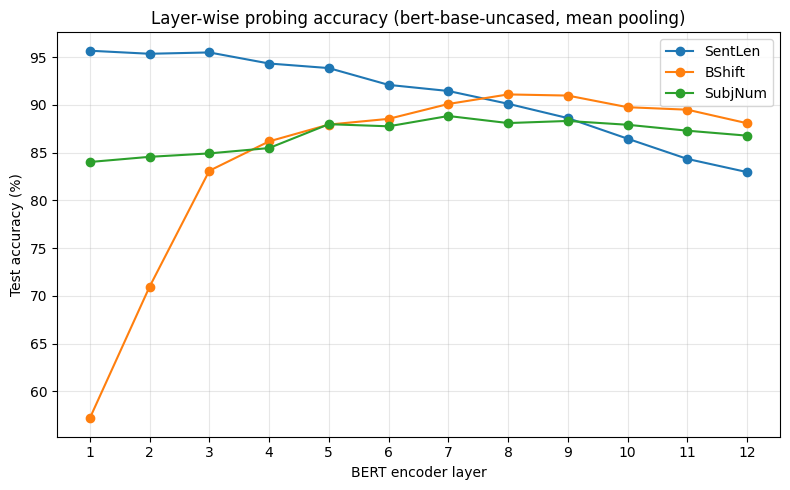

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, t in zip(axes, data):
    ax.plot(layers, np.array(results[t]) * 100, "o-", label="Test")
    ax.plot(layers, np.array(train_results[t]) * 100, "s--", alpha=0.5, label="Train")
    ax.axhline(100 / len(data[t]["labels"]), color="gray", ls=":", label="Chance")
    best = int(np.argmax(results[t]))
    ax.scatter([layers[best]], [results[t][best] * 100], s=140, facecolors="none", edgecolors="red", zorder=5)
    ax.set_title(t); ax.set_xlabel("BERT encoder layer"); ax.set_ylabel("Accuracy (%)")
    ax.set_xticks(layers); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("probing_per_task.png", dpi=150); plt.show()

plt.figure(figsize=(8, 5))
for t in data:
    plt.plot(layers, np.array(results[t]) * 100, "o-", label=t)
plt.xlabel("BERT encoder layer"); plt.ylabel("Test accuracy (%)"); plt.xticks(layers)
plt.title(f"Layer-wise probing accuracy ({MODEL_NAME}, {POOLING} pooling)")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.savefig("probing_comparison.png", dpi=150); plt.show()

## 6. Discussion

*Fill in after running; use the table and plots above.* Points worth addressing:

- **Reference results.** Conneau et al. (2018) report results for BiLSTM/Gated-ConvNet encoders (not BERT), where SentLen is easiest to recover from simple encoders, BShift is hard for bag-of-words style models (they cannot see word order, ~50% for CBOW) but much better for order-aware encoders, and SubjNum is solved moderately to well by most encoders.
- **Expected layer-wise trend for BERT** (see also Jawahar et al., 2019, *What does BERT learn about the structure of language?*): surface information (**SentLen**) is typically strongest in the lower layers and fades in higher ones; syntactic information (**BShift**) tends to peak in the middle layers; the semantic-ish **SubjNum** tends to be strongest in the middle-to-upper layers.
- **Check your own numbers.** Which layer is best for each task? Does accuracy drop at the top layers? Is BShift close to chance in the first layers (the word-order signal comes mostly from positional embeddings + self-attention)?
- **Sanity checks.** Compare train vs. test accuracy for over/under-fitting, and chance level (≈16.7% SentLen, 50% for the binary tasks).
- **Ablations to try:** `POOLING = "cls"` vs `"mean"`, a lighter BERT (`MODEL_NAME`), regularisation strength `C`, and including the embedding layer (layer 0) as a baseline.